# ❤️ HeartNet Inference Tutorial

### ⚠️ Prerequisites: Feature Extraction
**HeartNet** is designed to classify tissue based on histology feature embeddings. It does **not** accept raw images directly.

Before running this notebook, ensure you have processed your **H&E images** using the **UNI foundation model**.
* **Required Model:** [Mahmood Lab UNI](https://github.com/mahmoodlab/UNI)
* **Input Data:** The code below assumes you have already generated UNI embeddings (e.g., `.csv` or `.npy` files) for your slides.

In [1]:
import torch
import sys
import pandas as pd
import anndata as ad
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
import scanpy as sc

current_dir = os.getcwd()
src_path = os.path.abspath(os.path.join(current_dir, '..', 'src'))
if src_path not in sys.path:
    sys.path.append(src_path)

from heartnet.model import load_heartnet,predict_and_annotate
from heartnet.visualization import plot_umap_with_patches

BASE_DIR = os.path.abspath(os.path.join(current_dir, '..'))
CHECKPOINT_DIR = os.path.join(BASE_DIR, 'models', 'heartnet_weights')


TIMESTAMP = "heart_net" 

print(f"Reading model from: {CHECKPOINT_DIR}")


device = 'cuda' if torch.cuda.is_available() else 'cpu'

try:
    model, info = load_heartnet(CHECKPOINT_DIR, TIMESTAMP, device=device)
    print("Model loaded successfully!")
    print(f"Classes: {info['num_classes']}")
    print(f"Input Features: {info['input_dim']}")
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please check if .pth and .pkl files are in 'models/heartnet_weights'")


/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
/beegfs/home/mjoodaki/miniconda3/envs/PILO

Reading model from: /beegfs/home/mjoodaki/data/jupyter/Heart_code/git_heartnet/polyploid-heart/models/heartnet_weights
✅ HeartNet loaded successfully from heart_net
Model loaded successfully!
Classes: 9
Input Features: 50


### 📂 Load Example Data (Merfish 2)
In this step, we load the **UNI embeddings** for the **Merfish 2** sample.
This CSV file contains feature vectors extracted from H&E patches, which will serve as the input for **HeartNet**.

In [2]:
data=pd.read_csv('/beegfs/data/CostaLab/SpatialHeart/Merfish_2/WSI_patch_embeddings.csv')

### ⚙️ Data Preprocessing & Dimensionality Reduction
Here, we prepare the embeddings for the model:
1.  **Feature Extraction:** Select the first 1536 feature columns from the dataframe.
2.  **Scaling:** Apply `StandardScaler` to normalize features (zero mean, unit variance).
3.  **PCA:** Reduce dimensionality to **50 components** to capture the most important variations in the data.

In [6]:
X = data[data.columns[0:1536]].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  
n_components = 50  
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

### 📊 Data Visualization & Clustering (Scanpy)
In this step, we convert the data into an `AnnData` object to leverage **Scanpy** for visualization:
1.  **AnnData Creation:** storing features in `.X` and metadata in `.obs`.
2.  **Clustering:** constructing a neighborhood graph and applying **Leiden clustering** (resolution=0.3) to find inherent groups in the data.
3.  **UMAP:** visualizing the data structure in 2D space.

In [7]:
adata=ad.AnnData(X=data[data.columns[0:1536]].values,obs=data[data.columns[1536:-1]],obsm={'X_pca': X_pca})
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata,resolution=0.3)

/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


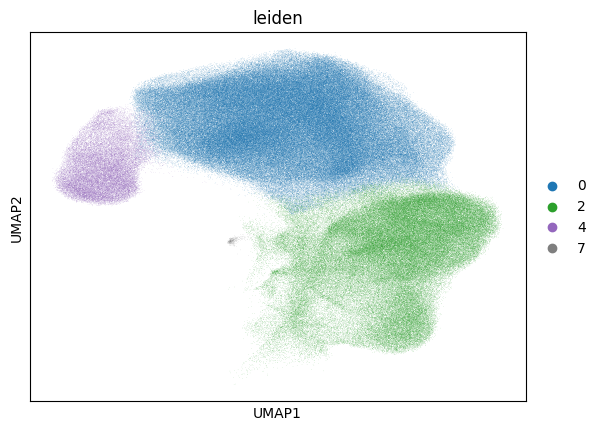

In [11]:
sc.pl.umap(adata,color='leiden')

### 🖼️ Visualization: Projecting H&E Patches on UMAP
In this visualization, we overlay the actual **H&E image patches** onto their corresponding UMAP coordinates. 
These are the raw inputs that were fed into the **UNI model** to generate the embeddings used for clustering. This allows us to qualitatively verify if the clusters correspond to distinct histological structures.

**Note:** The path `patch_base_folder` must point to the directory containing the original extracted patches.

Overlaying patches from: /beegfs/data/CostaLab/SpatialHeart/Merfish_2/output/


/beegfs/home/mjoodaki/data/jupyter/Heart_code/git_heartnet/polyploid-heart/src/heartnet/visualization.py:46: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_id = sample_ids[i]
/beegfs/home/mjoodaki/data/jupyter/Heart_code/git_heartnet/polyploid-heart/src/heartnet/visualization.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  patch_id = patch_ids[i]


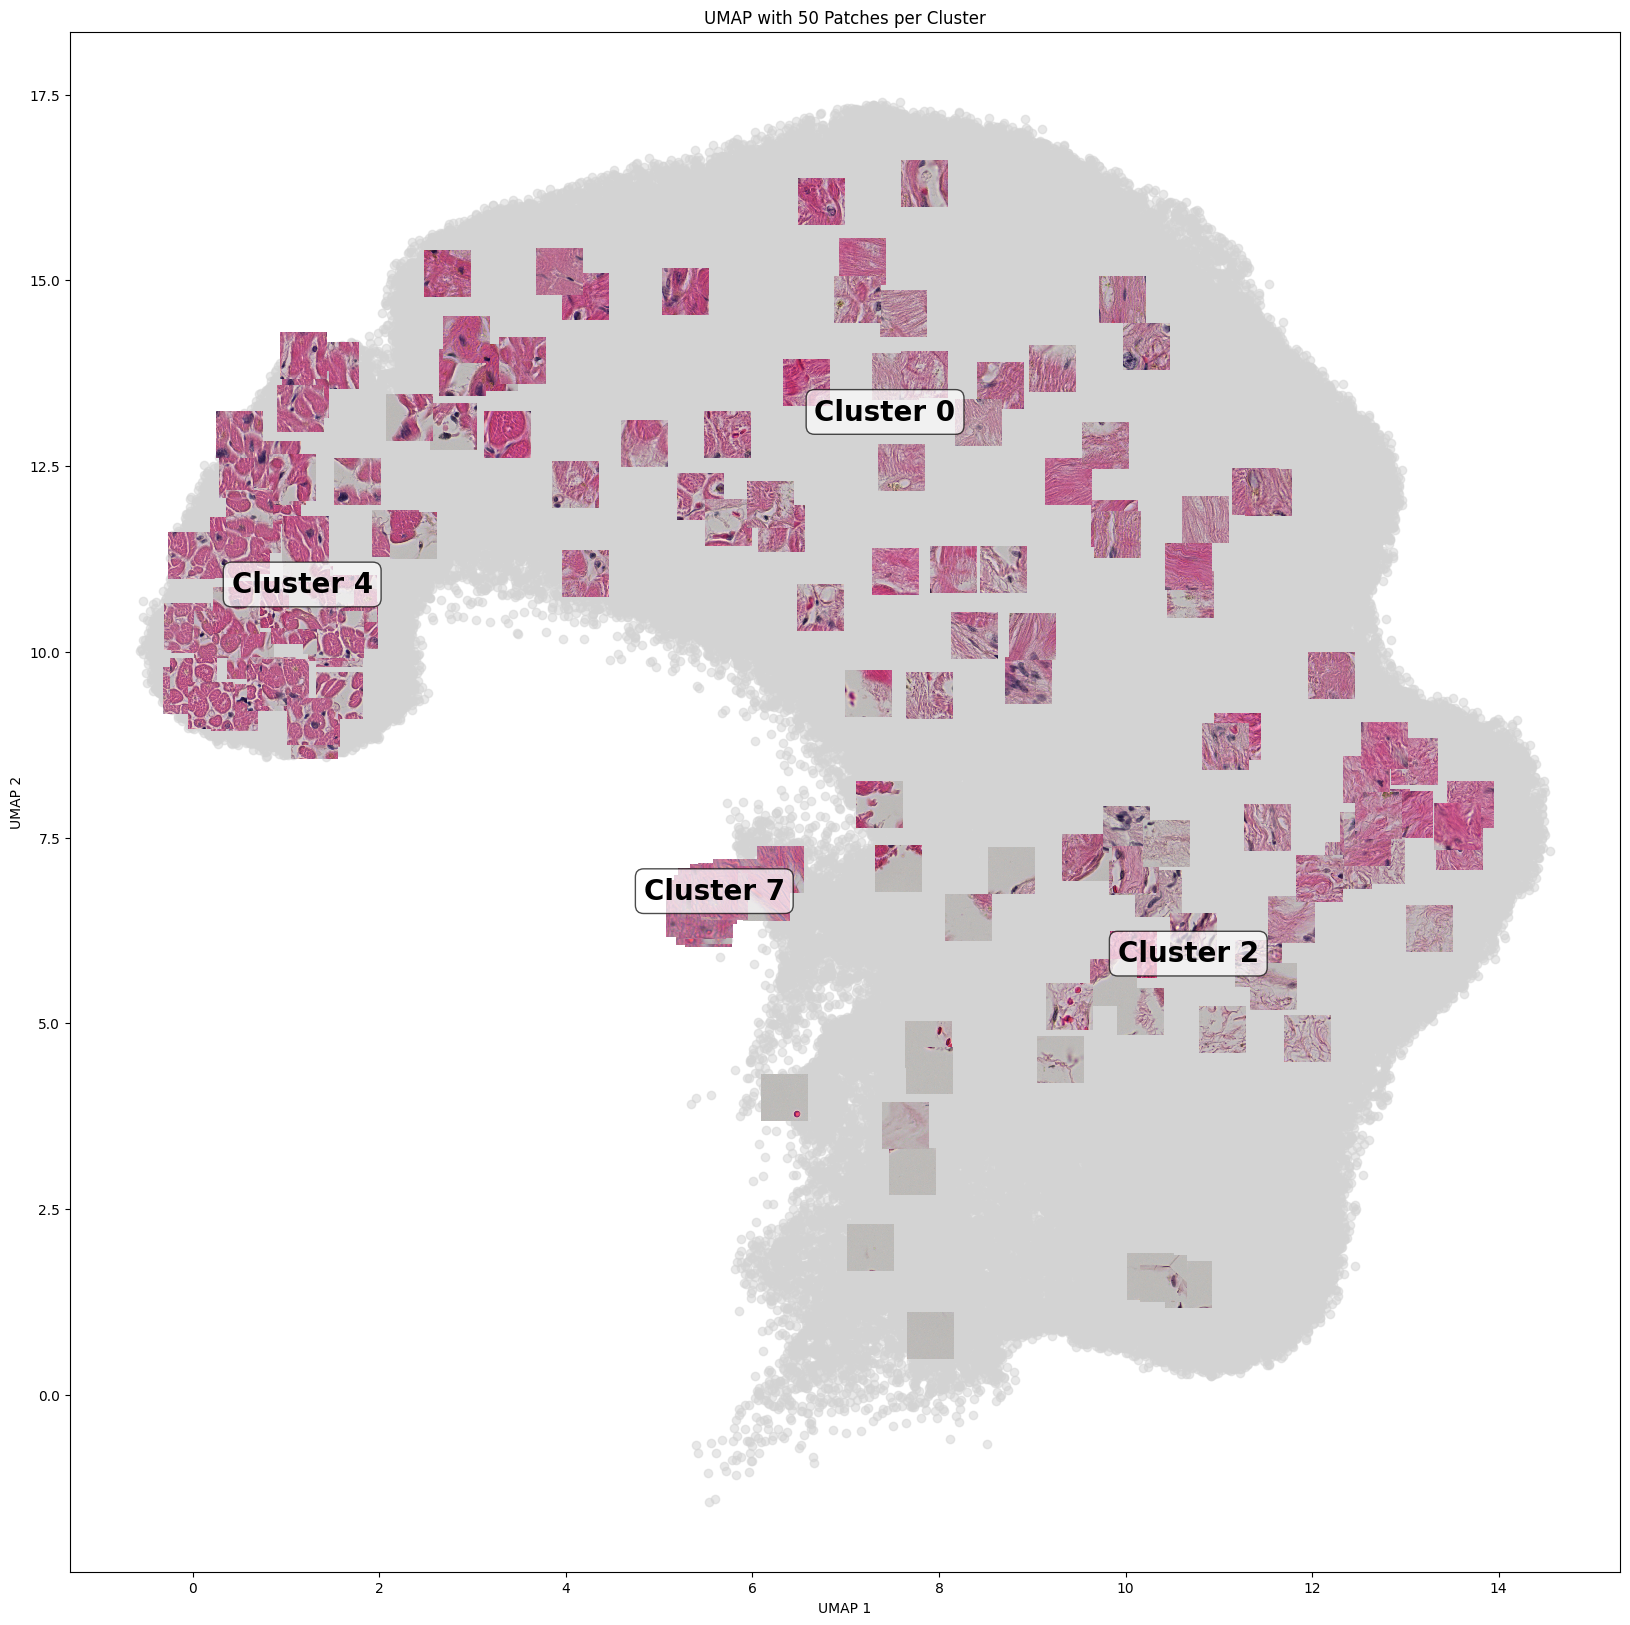

In [13]:
PATCH_FOLDER = "/beegfs/data/CostaLab/SpatialHeart/Merfish_2/output/"

fig = plot_umap_with_patches(
    adata, 
     slide_col="Slide_ID", 
      patch_col="Patch_ID_x", 
     cluster_col="leiden", 
    patch_base_folder=PATCH_FOLDER,
    zoom=0.5,      
    n_patches=50 ,
    figsize=(20, 20)
)

plt.show()
#fig.savefig('umap_patches.pdf')

### 🤖 HeartNet Inference
We now utilize the pre-trained **HeartNet** model to classify the tissue patches.
The `predict_and_annotate` function performs the following:
1.  Takes the processed features (e.g., PCA components) from the `AnnData` object.
2.  Runs the data through the neural network to get class probabilities.
3.  Assigns the tissue label with the highest probability to each patch.
4.  Stores the **Predicted Label** and **Confidence Score** directly into `adata.obs`

In [14]:
predict_and_annotate(
    model=model,
    adata=adata,
    class_names=info['class_names'], 
    input_key='X_pca',               
    device=device
)

print(adata.obs[['HeartNet_Pred', 'HeartNet_Confidence']].head())


Running inference on 526242 patches...
Predictions added to adata.obs['HeartNet_Pred']
          HeartNet_Pred  HeartNet_Confidence
1  damaged myocardium 1             0.907622
2  damaged myocardium 3             0.880618
4            myocardium             0.856003
5  damaged myocardium 3             0.839043
7  damaged myocardium 3             0.867256


/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/beegfs/home/mjoodaki/miniconda3/envs/PILOT-GM-VAE/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


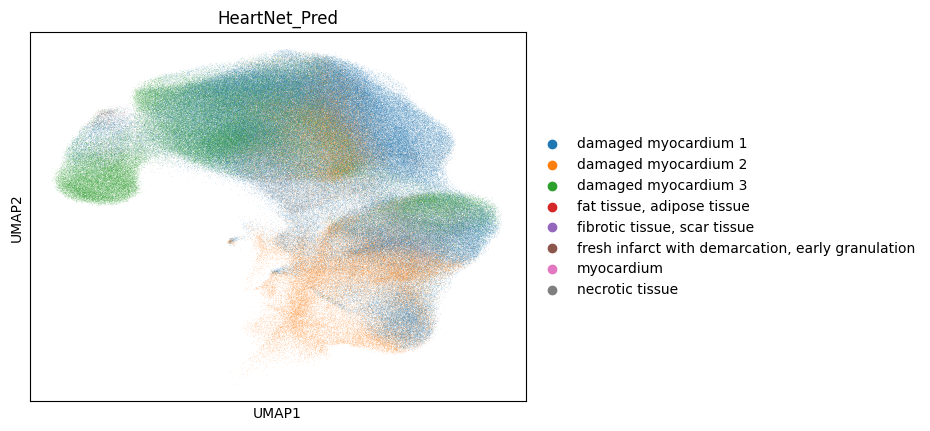

In [15]:
sc.pl.umap(adata,color='HeartNet_Pred')